OUTPUT of all methods with plot

# Functions and PreReqs

## installations

In [7]:
# dump the junk in dev/null

! pip install hdf5storage &> /dev/null
! pip install pytorch_lightning &> /dev/null


# don't use this test utils
# it's using its own test_utils
# ! pip install test_utils

!pip uninstall torchmetrics -y &> /dev/null
!pip install torchmetrics==0.7.0 &> /dev/null


# this is not found !pip install torchvision==0.8.2
! pip install torchvision &> /dev/null

## mount drive and ch dir and path insert

In [8]:
from google.colab import drive
drive.mount('/content/gdrive')
import sys
import os
os.chdir('/content/gdrive/My Drive/HPPP/')
print(f"Current working directory: {os.getcwd()}")
sys.path.insert(0, '/content/gdrive/My Drive/HPPP/Prox_PnP')
sys.path.insert(0, '/content/gdrive/My Drive/HPPP/Prox_PnP/PnP_restoration')
sys.path.insert(0, '/content/gdrive/My Drive/HPPP/Prox_PnP/PnP_restoration/utils')
sys.path.insert(0, '/content/gdrive/My Drive/HPPP/Prox_PnP/PnP_restoration/kernels')
sys.path.insert(0, '/content/gdrive/My Drive/HPPP/Prox_PnP/PnP_restoration/Levin09.mat')
sys.path.insert(0, '/content/gdrive/My Drive/HPPP/Prox_PnP/PnP_restoration/models')
sys.path.insert(0, '/content/gdrive/My Drive/HPPP/Prox_PnP/PnP_restoration/GS_denoising')
sys.path.insert(0, '/content/gdrive/My Drive/HPPP/Prox_PnP/PnP_restoration/GS_denoising/models')
sys.path.insert(0, '/content/gdrive/My Drive/HPPP/Prox_PnP/PnP_restoration/datasets')
sys.path.insert(0, '/content/gdrive/My Drive/HPPP/Provable_PnP')
sys.path.insert(0, '/content/gdrive/My Drive/HPPP/Provable_PnP/utils')
sys.path.insert(0, '/content/gdrive/My Drive/HPPP/Provable_PnP/model')
sys.path.insert(0, '/content/gdrive/My Drive/HPPP/Provable_PnP/training')
sys.path.insert(0, '/content/gdrive/My Drive/HPPP/Provable_PnP/Pretrained_models')


Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).
Current working directory: /content/gdrive/My Drive/HPPP


## imports

In [9]:
import numpy as np
import hdf5storage
import argparse
import cv2
import sys
import torch
import scipy.io as scio
import torch.nn as nn
import matplotlib.pyplot as plt

from Prox_PnP.PnP_restoration.utils.utils_restoration import matlab_style_gauss2D, imread_uint
from argparse import ArgumentParser
from scipy import ndimage

# I'll implement it in the small function parts since it's just a simple function
# from PnP_restoration.utils.utils_restoration import array2tensor

from Prox_PnP.PnP_restoration.utils import RGB_utils_sr as utils_sr

In [10]:
! pwd

/content/gdrive/My Drive/HPPP


## Parsers

In [ ]:
parser = argparse.ArgumentParser()
parser.add_argument('--task', type=str, default='Gaussian-deblurring', help='image deblurring or super-resolution')###Gaussian-deblurring; Uniform-deblurring; Super-resolution
parser.add_argument('--scale', type=int, default=1, help='image scale')
parser.add_argument('--ycbcr', type=str, choices=['True', 'False'], default='False', help='Enable YCbCr mode')
# we changed it since CRED sucks, But we have to do it anyway
# parser.add_argument('--algo', type=str, default='CRED', help='algorithms')
parser.add_argument('--algo', type=str, default='GraRED_HP3', help='algorithms')
parser.add_argument('--dataset', type=str, default='set12', help='algorithms')
parser.add_argument('--noise_level', type=float, default=5.1, help='noise level of image')
args = parser.parse_args([]) # Pass an empty list to parse_args() to ignore kernel arguments

## Functions

### PreReqFunctions

In [ ]:
# file: initialize_prox.py
# Prepares the Fourier-domain constants for the data-fidelity proximal step
# of the HPPP / GraRED-HP3 loop. [REF: chapter/lemma of the data sub-problem]

def initialize_prox(img, degradation_mode, degradation, sf, device):
    # Kernel as a float64 tensor (1, 1, H_k, W_k).
    k = degradation
    k_tensor = array2tensor(np.expand_dims(k, 2)).double().to(device)

    # Broadcast the kernel to all color channels.

    if img.shape[1] > 1:
        k_tensor = k_tensor.repeat(1, img.shape[1], 1, 1)

    # Convolution-type: precompute the constant FFT factors once.

    if degradation_mode in ['deblurring', 'SR']:
        FB, FBC, F2B, FBFy = utils_sr.pre_calculate_prox(img, k_tensor, sf)
        return FB, FBC, F2B, FBFy, k_tensor

    # Inpainting: mask operator, no Fourier precomputation needed.

    elif degradation_mode == 'inpainting':
        return None, None, None, None, k_tensor

    # Defensive: unknown mode.

    else:
        return None, None, None, None, None


In [ ]:
# Evaluates the data-fidelity term f(y) = 0.5 * ||img - A(y)||_2^2 in torch.
# The kernel is flipped along both spatial dims (imfilter computes
# correlation, so flipping yields the true convolution k * y) and expanded
# to 3 channels. 'SR' additionally subsamples by sf; other modes are not
# implemented. [REF: data-fidelity term, Chapter X]
def calulate_data_term(k_tensor,degradation_mode, sf,y,img):
        '''
        Calculation of the data term value f(y)
        :param y: Point where to evaluate F
        :param img: Degraded image
        :return: f(y)
        '''
#         k_tensor = array2tensor(np.expand_dims(k, 2)).double().to(device)
        if degradation_mode == 'deblurring':
            deg_y = utils_sr.imfilter(y.double(), k_tensor[0].double().flip(1).flip(2).expand(3, -1, -1, -1))
            f = 0.5 * torch.norm(img - deg_y, p=2) ** 2
        elif degradation_mode == 'SR':
            deg_y = utils_sr.imfilter(y.double(), k_tensor[0].double().flip(1).flip(2).expand(3, -1, -1, -1))
            deg_y = deg_y[..., 0::sf, 0::sf]
            f = 0.5 * torch.norm(img - deg_y, p=2) ** 2
#         elif degradation_mode == 'inpainting':
#             deg_y = M * y.double()
#             f = 0.5 * torch.norm(img - deg_y, p=2) ** 2
        else:
            print('degradation not implemented')
        return f


In [ ]:
# Evaluates the data-fidelity term f = 0.5 * ||img - A(y)||_2^2 at the current
# estimate y, where A is the forward degradation operator: blur convolution
# ('deblurring'), blur + downsampling by sf ('SR'), or element-wise masking
# ('inpainting'). Returns 0 for unknown modes. [REF: data-fidelity term, Chapter X]
def calulate_data_term(k_tensor, degradation_mode, sf, y, img):
    if degradation_mode == 'deblurring':
        deg_y = utils_sr.imfilter(y.double(), k_tensor)
        f_val = 0.5 * torch.norm(img - deg_y, p=2) ** 2
    elif degradation_mode == 'SR':
        deg_y = utils_sr.imfilter(y.double(), k_tensor)
        deg_y = deg_y[..., 0::sf, 0::sf]
        f_val = 0.5 * torch.norm(img - deg_y, p=2) ** 2
    elif degradation_mode == 'inpainting':
        deg_y = y.double() * k_tensor
        f_val = 0.5 * torch.norm(img - deg_y, p=2) ** 2
    else:
        f_val = 0
    return f_val


In [ ]:
# Color-space utility: converts an RGB image to YCbCr, matching MATLAB's
# rgb2ycbcr (ITU-R BT.601, studio swing); with only_y=True returns just the
# luma channel Y — the channel the restoration loop operates on. Inverse
# partner of ycbcr2rgb. Accepts uint8 [0, 255] or float [0, 1]; output dtype
# matches the input.
def rgb2ycbcr(img, only_y=True):
    '''same as matlab rgb2ycbcr
    only_y: only return Y channel
    Input:
        uint8, [0, 255]
        float, [0, 1]
    '''
    in_img_type = img.dtype
    img.astype(np.float32)
    if in_img_type != np.uint8:
        img *= 255.
    # convert
    if only_y:
        rlt = np.dot(img, [65.481, 128.553, 24.966]) / 255.0 + 16.0
    else:
        rlt = np.matmul(img, [[65.481, -37.797, 112.0], [128.553, -74.203, -93.786],
                              [24.966, 112.0, -18.214]]) / 255.0 + [16, 128, 128]
    if in_img_type == np.uint8:
        rlt = rlt.round()
    else:
        rlt /= 255.
    return rlt.astype(in_img_type)


In [ ]:
# Color-space utility: converts a YCbCr image (H, W, 3) back to RGB, matching
# MATLAB's ycbcr2rgb (ITU-R BT.601, studio swing). Used to map restoration
# results processed on the Y channel back to color space for display/saving.
# Accepts uint8 in [0, 255] or float in [0, 1]; output dtype matches the input
def ycbcr2rgb(img):
    '''same as matlab ycbcr2rgb
    Input:
        uint8, [0, 255]
        float, [0, 1]
    '''
    in_img_type = img.dtype
    img.astype(np.float32)
    if in_img_type != np.uint8:
        img *= 255.
    # convert
    rlt = np.matmul(img, [[0.00456621, 0.00456621, 0.00456621], [0, -0.00153632, 0.00791071],
                          [0.00625893, -0.00318811, 0]]) * 255.0 + [-222.921, 135.576, -276.836]
    rlt = np.clip(rlt, 0, 255)
    if in_img_type == np.uint8:
        rlt = rlt.round()
    else:
        rlt /= 255.
    return rlt.astype(in_img_type)


### small functions

In [ ]:
# Converts a float image in [0, 1] to uint8 in [0, 255].
def single2uint(img):
    return np.uint8(img*255.)

# Converts a PyTorch tensor in [0, 1] (CHW or HW) to a uint8 numpy image
# (HWC or HW), clamping to [0, 1] and rounding to integers.
def tensor2uint(img):
    img = img.data.squeeze().float().clamp_(0, 1).cpu().numpy()
    if img.ndim == 3:
        img = np.transpose(img, (1, 2, 0))
    return np.uint8((img*255.0).round())

# Same as tensor2uint, but min-max normalizes (norm_proj) instead of clamping;
# used when the tensor range is not guaranteed to be exactly [0, 1].
def tensor2uint2(img):
    img = img.data.squeeze().float().cpu().numpy()
    img = norm_proj(img)
    if img.ndim == 3:
        img = np.transpose(img, (1, 2, 0))
    return np.uint8((img*255.0).round())

# Converts a PyTorch tensor to a float numpy image in [0, 1] (clamped),
# without uint8 quantization; CHW is transposed to HWC.
def tensor2float(img):
    img = img.data.squeeze().float().clamp_(0, 1).cpu().numpy()
    if img.ndim == 3:
        img = np.transpose(img, (1, 2, 0))
    return img

# Same as tensor2float, but min-max normalizes instead of clamping.
def tensor2float2(img):
    img = img.data.squeeze().float().cpu().numpy()
    img = norm_proj(img)
    if img.ndim == 3:
        img = np.transpose(img, (1, 2, 0))
    return img

# PSNR in dB between two images in [0, 255]; `border` pixels are cropped from
# each side before comparison (usual SR evaluation convention). Returns inf
# for identical images.
def calculate_psnr(img1, img2, border=0):
    # img1 and img2 have range [0, 255]
    if not img1.shape == img2.shape:
        raise ValueError('Input images must have the same dimensions.')
    h, w = img1.shape[:2]
    img1 = img1[border:h-border, border:w-border]
    img2 = img2[border:h-border, border:w-border]

    img1 = img1.astype(np.float64)
    img2 = img2.astype(np.float64)
    mse = np.mean((img1 - img2)**2)
    if mse == 0:
        return float('inf')
    return 20 * np.log10(255.0 /np.sqrt(mse))

# Gradient of the data-fidelity term, evaluated in closed form in the Fourier
# domain via the precomputed factors (FB, FBC, FBFy) from initialize_prox;
# sf is 1 for 'deblurring' and the SR scale factor otherwise.
# [REF: gradient of the data term, Chapter X]
def calculate_grad(img, degradation_mode, FB, FBC,FBFy,sf=1):
    if degradation_mode == 'deblurring':
        grad = utils_sr.grad_solution(img.double(), FB, FBC, FBFy, 1)
    if degradation_mode == 'SR' :
        grad = utils_sr.grad_solution(img.double(), FB, FBC, FBFy, sf)
    return grad

# Creates `path` (and parents) if it does not exist yet.
def mkdir(path):
    if not os.path.exists(path):
        os.makedirs(path)

# Min-max normalization of a numpy array to [0, 1].
def norm_proj(x):
    x = (x-np.min(x))/(np.max(x)-np.min(x))
    return x

# Saves an image with OpenCV; swaps RGB to BGR for 3-channel images since
# cv2.imwrite expects BGR order.
def imsave(img, img_path):
    if img.ndim == 3:
        img = img[:, :, [2, 1, 0]]
    cv2.imwrite(img_path, img)


In [ ]:
# Forward degradation operator A in numpy: blur with kernel k (wrap boundary,
# i.e. circular convolution — consistent with the FFT-based closed forms)
# followed by downsampling with stride sf starting at offset 0. Maps an HR
# image to its LR observation, e.g. for generating synthetic degradations.
def numpy_degradation(x, k, sf=3):
    ''' blur + downsampling
    Args:
        x: HxWxC image, [0, 1]/[0, 255]
        k: hxw, double, positive
        sf: down-scale factor
    Return:
        downsampled LR image
    '''
    x = ndimage.filters.convolve(x, np.expand_dims(k, axis=2), mode='wrap')
    st = 0
    return x[st::sf, st::sf, ...]


In [ ]:
# Converts a numpy image (H, W, C) to a torch tensor (1, C, H, W): permutes
# HWC to CHW and adds the batch axis. Entry point of the numpy-to-torch
# boundary, e.g. for kernels and images entering the tensor pipeline.
def array2tensor(img):
    '''
    permutes to bring the channel dimension to the first and unsqueezes to put it in the batch dimension
    '''
    return torch.from_numpy(img).permute(2, 0, 1).unsqueeze(0)

In [ ]:
# Euclidean projection of x onto the L2 ball of the given radius centered at
# y: x is rescaled onto the sphere y + radius*(x-y)/||x-y|| only if it lies
# outside the ball, otherwise it is returned unchanged. Closed form of the
# proximal step for a ball constraint. [REF: ball-constraint step, Chapter X]
def Projection_On_L2_Ball(x, y, radius):
    # x: point to project
    # y: center of the ball
    # radius: radius of the ball
    if torch.norm(x-y, p=2) > radius:
        Px = y + (x-y)/torch.norm(x-y, p=2)*radius
    else:
        Px = x
    return Px


In [ ]:
# One step of the relaxed projected Landweber iteration for the data-
# consistency constraint ||A x - y|| <= delta, where A = downsample o blur is
# applied entirely in the Fourier domain via the factors (FB, FBC) from
# initialize_prox. T is the projection onto the L2 ball around y (see
# Projection_On_L2_Ball): if Ax violates the ball, x moves along
# A*(T(Ax)-Ax) with the adaptive relaxed step
# lambda_k * ||T(Ax)-Ax||^2 / ||A*(T(Ax)-Ax)||^2 (lambda_k in (0, 1]);
# otherwise x is already feasible and stays unchanged.
# [REF: Landweber / feasibility step, Chapter X]
def Landweber_operator(x, y, FB, FBC, delta, lambda_k=1, sf=1):
    ###Lx = x+||T(Ax)-Ax||^2/(||A*(T(Ax)-Ax)||^2) A*(T(Ax)-Ax)
    ###alpha: relaxed parameter (0,1]
    ###Ax####

    FBFx = FB.mul(torch.fft.fftn(x, dim=(-2,-1)))
    AFx = utils_sr.downsample(torch.fft.ifftn(FBFx, dim=(-2,-1)),sf=sf)
    ####T(Ax)####
    TAx = Projection_On_L2_Ball(AFx, y, delta)
    TAx_norm = torch.norm(TAx-AFx, p=2)**2
    ####A*(T(Ax)-Ax)####
    r = TAx - AFx
    STr = utils_sr.upsample(r, sf=sf)

    FBCSTr = FBC.mul(torch.fft.fftn(STr, dim=(-2,-1)))
    AstarFBCSTr = torch.real(torch.fft.ifftn(FBCSTr, dim=(-2,-1)))
    AstarFBCSTr_norm = torch.norm(AstarFBCSTr, p=2)**2
    if torch.norm(AFx-y, p=2) > delta:
        Lx = x +lambda_k* TAx_norm/AstarFBCSTr_norm*AstarFBCSTr
    else:
        Lx = x
    return Lx


In [ ]:
# Loads the pretrained grayscale gradient-step denoiser (GS-DRUNet from the
# ProxPnP codebase) used as the deep prior in the plug-and-play / RED loop.
# Builds the GradMatch module with fixed hyper-params (act_mode='E',
# grayscale=True), loads the checkpoint, and returns the model in eval mode
# with all parameters frozen (inference-only prior).
# [REF: deep denoiser prior, Chapter X]
def initialize_cuda_gray_denoiser(device):
    '''
    Initialize the denoiser model with the given pretrained ckpt
    '''
    sys.path.append('./ProxPnP/GS_denoising/')
    # Fixed relative import to absolute import
    # from .lightning_GSDRUNet import GradMatch
    from Prox_PnP.GS_denoising.lightning_denoiser import GradMatch

    parser2 = ArgumentParser(prog='utils_restoration.py')
    parser2 = GradMatch.add_model_specific_args(parser2)
    parser2 = GradMatch.add_optim_specific_args(parser2)
    hparams = parser2.parse_known_args()[0]
    hparams.act_mode = 'E'
    hparams.grayscale = True
    denoiser_model = GradMatch(hparams)
    # print(self.hparams.pretrained_checkpoint)

    # changed it! (:
    # hparams.pretrained_checkpoint = './Prox_PnP/GS_denoising/ckpts/GSDRUNet_grayscale.ckpt'
    # hparams.pretrained_checkpoint = './Prox_PnP/GS_denoising/ckpts/GS_DRUNet.ckpt'
    hparams.pretrained_checkpoint = './Prox_PnP/GS_denoising/ckpts/GSDRUNet.ckpt'

    # we changed it (:
    # checkpoint = torch.load(hparams.pretrained_checkpoint, map_location=device)
    checkpoint = torch.load(hparams.pretrained_checkpoint, map_location=device, weights_only= False)
    # we changed it due to the KeyError
    denoiser_model.load_state_dict(checkpoint['state_dict'],strict=False)

    denoiser_model.load_state_dict(checkpoint,strict=False)

    denoiser_model.eval()
    for i, v in denoiser_model.named_parameters():
        v.requires_grad = False
    denoiser_model = denoiser_model.to(device)
    return denoiser_model

In [ ]:
# Color (RGB) variant of initialize_cuda_gray_denoiser: loads the pretrained
# gradient-step denoiser for 3-channel inputs (grayscale=False) as the deep
# prior in the plug-and-play / RED loop. Same build/checkpoint/freeze flow;
# the redundant second load_state_dict is commented out.
# [REF: deep denoiser prior, Chapter X]
def initialize_cuda_color_denoiser(device):
    '''
    Initialize the denoiser model with the given pretrained ckpt (RGB Mode)
    '''
    import sys
    sys.path.append('./ProxPnP/GS_denoising/')
    from Prox_PnP.GS_denoising.lightning_denoiser import GradMatch

    parser2 = ArgumentParser(prog='utils_restoration.py')
    parser2 = GradMatch.add_model_specific_args(parser2)
    parser2 = GradMatch.add_optim_specific_args(parser2)
    hparams = parser2.parse_known_args()[0]
    hparams.act_mode = 'E'

    # --- Key change 1: switch from grayscale to RGB mode ---
    hparams.grayscale = False

    denoiser_model = GradMatch(hparams)

    # --- Key change 2: path to the color model weights ---
    # If you have a GSDRUNet_color.ckpt (or similar), put its path here
    hparams.pretrained_checkpoint = './Prox_PnP/GS_denoising/ckpts/GSDRUNet.ckpt'

    checkpoint = torch.load(hparams.pretrained_checkpoint, map_location=device, weights_only=False)

    # Load the weights
    denoiser_model.load_state_dict(checkpoint['state_dict'], strict=False)
    # denoiser_model.load_state_dict(checkpoint, strict=False)

    denoiser_model.eval()
    for i, v in denoiser_model.named_parameters():
        v.requires_grad = False
    denoiser_model = denoiser_model.to(device)
    return denoiser_model

In [ ]:
# Loads a pretrained grayscale denoiser from the Provable PnP model zoo to
# serve as the prior D_sigma in the plug-and-play loop. `model_type` selects
# the architecture (plain DnCNN / SimpleCNN / spectrally-normalized RealSN /
# FNE / MMO-SPCnet variants) and `sigma` the noise level of the checkpoint;
# some branches override the default checkpoint path. Returns the model in
# eval mode. [REF: PnP denoiser prior, Chapter X]
def load_model(model_type, sigma, device):
    os.chdir('/content/gdrive/My Drive/HPPP')
    path = "./Provable_PnP/Pretrained_models/" + model_type + "_noise" + str(sigma) + ".pth"
    if model_type == "DnCNN":
        from Provable_PnP.model.models import DnCNN
        net = DnCNN(channels=1, num_of_layers=17)
        model = nn.DataParallel(net).cuda()
    elif model_type == "SimpleCNN":
        from Provable_PnP.model.SimpleCNN_models import DnCNN
        model = DnCNN(1, num_of_layers = 4, lip = 0.0, no_bn = True).cuda()
    elif model_type == "RealSN_DnCNN":
        from Provable_PnP.model.realSN_models import DnCNN
        net = DnCNN(channels=1, num_of_layers=17)
        model = nn.DataParallel(net).cuda()
    elif model_type == "FNE_DnCNN":
        from Provable_PnP.model.full_realsn_models import FNE_DnCNN as DnCNN
        net = DnCNN(channels=1, num_of_layers=17).cuda()
        path = './Pretrained_models2/FNE_DnCNN_5/best_model.pth'
        # path ='./Pretrained_models2/FNE_DnCNN/epoch46_noise5_PSNR34.54_SSIM0.89.pth'
        model = net.cuda(device.index)
        # model = nn.DataParallel(net).cuda()
    elif model_type == "RealSN_SimpleCNN":
        from Provable_PnP.model.SimpleCNN_models import DnCNN
        model = DnCNN(1, num_of_layers = 4, lip = 1.0, no_bn = True).cuda()
    elif model_type == "MMO":
        from training.spc_models import simple_DnCNN
        model = simple_DnCNN(n_ch_in=1, n_ch_out=1, n_ch=64, nl_type='softplus', depth=20, bn=False).cuda()
        path ='./Pretrained_models2/SPCnet_sn_iters_10_0.8/best_model.pth'
        # path = './Pretrained_models2/SPCnet_MMO/epoch6_noise[0, 25]_PSNR34.01_SSIM0.89_128hc.pth'
    else:
        from Provable_PnP.model.realSN_models import DnCNN
        net = DnCNN(channels=1, num_of_layers=17)
        model = nn.DataParallel(net).cuda()

    model.load_state_dict(torch.load(path))
    model.eval()
    return model


### Different Algorithms

In [ ]:
# ==========================================
# 7. Algorithm SCFP_LFP_PnP
# ==========================================
def SCFP_LFP_PnP(x0, y, k_tensor, degradation_mode, FB, FBC, f, opt):
    K = opt['K']
    alpha = opt['alpha']
    beta = opt['beta']
    sigma = opt['sigma']
    sigma_norm = opt['sigma_norm']
    Sf = opt['sf']
    obj_fun = np.zeros(K)
    PSNR = []

    for i in range(K):
        x = x0
        psnr = calculate_psnr(tensor2uint(x), opt['gt'])
        PSNR.append(psnr)

        # --- Adding condition Inpainting ---
        if degradation_mode == 'inpainting':
            grad1 = k_tensor * (k_tensor * x.double() - y.double()) / (sigma**2)
            Lx = x - alpha * grad1
        else:
            Lx = Landweber_operator(x, y, FB, FBC, sigma_norm, alpha, sf=Sf)

        f_est = Lx
        mintmp = torch.min(f_est)
        maxtmp = torch.max(f_est)
        xtilde = (f_est - mintmp) / (maxtmp - mintmp)
        scale_range = 1.0 + sigma/255.0/2.0
        scale_shift = (1 - scale_range) / 2.0
        xtilde = xtilde * scale_range + scale_shift

        # --- Channel Processing ---
        with torch.enable_grad():
            R = f(xtilde[:, 0:1, :, :].detach().clone().requires_grad_(True).float())
            G = f(xtilde[:, 1:2, :, :].detach().clone().requires_grad_(True).float())
            B = f(xtilde[:, 2:3, :, :].detach().clone().requires_grad_(True).float())
            r = torch.cat((R, G, B), dim=1).detach()

        z = xtilde - r
        z = (z - scale_shift) / scale_range
        z = z * (maxtmp - mintmp) + mintmp
        z = (1-beta)*f_est+beta*z

        z = torch.nan_to_num(z, nan=0.0, posinf=1.0, neginf=0.0)
        z = torch.clamp(z, 0.0, 1.0)
        x0 = z

        obj_fun[i] = calulate_data_term(k_tensor, degradation_mode, Sf, x0, y).float().cpu().numpy()
    return x0, obj_fun, PSNR

# ==========================================
# 8. Algorithm SAM_PRO_v2
# ==========================================
def SAM_PRO_v2(x0, y, k_tensor, degradation_mode, FB, FBC, FBFy, f, opt):
    K = opt['K']
    alpha = opt['alpha']
    beta = opt['beta']
    sigma = opt['sigma']
    mu_0 = opt['mu_0']
    Sf = opt['sf']
    obj_fun = np.zeros(K)
    residual = torch.zeros(K)
    PSNR = []

    for i in range(K):
        x = x0
        psnr = calculate_psnr(tensor2uint(x), opt['gt'])
        PSNR.append(psnr)
        mu_k = mu_0*(i+1)**(-1.0)
        mu = mu_k if mu_k<1 else 1
        f_est = x
        mintmp = torch.min(f_est)
        maxtmp = torch.max(f_est)
        xtilde = (f_est - mintmp) / (maxtmp - mintmp)
        scale_range = 1.0 + sigma/255.0/2.0
        scale_shift = (1 - scale_range) / 2.0
        xtilde = xtilde * scale_range + scale_shift

        # --- Channel Processing ---
        with torch.enable_grad():
            R = f(xtilde[:, 0:1, :, :].detach().clone().requires_grad_(True).float())
            G = f(xtilde[:, 1:2, :, :].detach().clone().requires_grad_(True).float())
            B = f(xtilde[:, 2:3, :, :].detach().clone().requires_grad_(True).float())
            r = torch.cat((R, G, B), dim=1).detach()

        z = xtilde - r
        z = (z - scale_shift) / scale_range
        z = z * (maxtmp - mintmp) + mintmp
        z = (1-beta)*f_est+beta*z

        # --- Gradient correction for Inpainting ---
        if degradation_mode == 'inpainting':
            grad = k_tensor * (k_tensor * z.double() - y.double()) / (sigma**2)
            v_est = z - mu * grad
        else:
            grad = calculate_grad(z, degradation_mode, FB, FBC, FBFy, sf=Sf)
            v_est = z - mu * grad / sigma

        v_est = torch.nan_to_num(v_est, nan=0.0, posinf=1.0, neginf=0.0)
        w = torch.clamp(v_est, 0.0, 1.0)

        residual[i] = torch.norm(w-x0, p=2)
        x0 = w
        obj_fun[i] = calulate_data_term(k_tensor, degradation_mode, Sf, x0, y).float().cpu().numpy()
    return x0, obj_fun, residual.float().cpu().numpy(), PSNR

# ==========================================
# 9. Algorithm PnP_FBS
# ==========================================
def PnP_FBS(x0, y, k_tensor, degradation_mode, FB, FBC, FBFy, f, opt):
    K = opt['K']
    beta = opt['beta']
    sigma = opt['sigma']
    Sf = opt['sf']
    obj_fun = np.zeros(K)
    residual = torch.zeros(K)
    mu0 = 4
    PSNR = []

    for i in range(K):
        x = x0
        psnr = calculate_psnr(tensor2uint(x), opt['gt'])
        PSNR.append(psnr)
        obj_fun[i] = 1/sigma**2 * calulate_data_term(k_tensor, degradation_mode, Sf, x0, y).float().cpu().numpy()
        mu = mu0

        # --- Gradient correction for Inpainting ---
        if degradation_mode == 'inpainting':
            grad1 = k_tensor * (k_tensor * x.double() - y.double()) / (sigma**2)
        else:
            grad1 = calculate_grad(x, degradation_mode, FB, FBC, FBFy, sf=Sf)

        f_est = x - mu * grad1

        # --- Channel Processing ---
        with torch.enable_grad():
            R = f(f_est[:, 0:1, :, :].detach().clone().requires_grad_(True).float())
            G = f(f_est[:, 1:2, :, :].detach().clone().requires_grad_(True).float())
            B = f(f_est[:, 2:3, :, :].detach().clone().requires_grad_(True).float())
            denoised_f_est = torch.cat((R, G, B), dim=1).detach()

        v_est = beta*(f_est - denoised_f_est)+(1-beta)*f_est
        v_est = torch.nan_to_num(v_est, nan=0.0, posinf=1.0, neginf=0.0)
        w = torch.clamp(v_est, 0.0, 1.0)

        residual[i] = torch.norm(w-x0, p=2)
        x0 = w
    return x0, obj_fun, residual.float().cpu().numpy(), PSNR

# ==========================================
# 10. Algorithm SAM_PRO_v1
# ==========================================
def SAM_PRO_v1(x0, y, k_tensor, degradation_mode, FB, FBC, FBFy, f, opt):
    K = opt['K']
    alpha = opt['alpha']
    beta = opt['beta']
    sigma = opt['sigma']
    mu_0 = opt['mu_0']
    Sf = opt['sf']
    obj_fun = np.zeros(K)
    residual = torch.zeros(K)
    PSNR = []

    for i in range(K):
        x = x0
        psnr = calculate_psnr(tensor2uint(x), opt['gt'])
        PSNR.append(psnr)
        mu_k = mu_0*(i+1)**(-1.0)
        mu = mu_k if mu_k<1 else 1
        f_est = x
        mintmp = torch.min(f_est)
        maxtmp = torch.max(f_est)
        xtilde = (f_est - mintmp) / (maxtmp - mintmp)
        scale_range = 1.0 + sigma/255.0/2.0
        scale_shift = (1 - scale_range) / 2.0
        xtilde = xtilde * scale_range + scale_shift

        # --- Channel Processing ---
        with torch.enable_grad():
            R = f(xtilde[:, 0:1, :, :].detach().clone().requires_grad_(True).float())
            G = f(xtilde[:, 1:2, :, :].detach().clone().requires_grad_(True).float())
            B = f(xtilde[:, 2:3, :, :].detach().clone().requires_grad_(True).float())
            r = torch.cat((R, G, B), dim=1).detach()

        z = xtilde - r
        z = (z - scale_shift) / scale_range
        z = z * (maxtmp - mintmp) + mintmp
        z = (1-beta)*f_est+beta*z

        # --- Gradient correction for Inpainting ---
        if degradation_mode == 'inpainting':
            grad = k_tensor * (k_tensor * f_est.double() - y.double()) / (sigma**2)
            v_est = f_est - alpha * grad
        else:
            grad = calculate_grad(f_est, degradation_mode, FB, FBC, FBFy, sf=Sf)
            v_est = f_est - alpha * grad / sigma

        v_est = torch.nan_to_num(v_est, nan=0.0, posinf=1.0, neginf=0.0)
        w = torch.clamp((1-mu)*z+mu*v_est, 0.0, 1.0)

        residual[i] = torch.norm(w-x0, p=2)
        x0 = w
        obj_fun[i] = calulate_data_term(k_tensor, degradation_mode, Sf, x0, y).float().cpu().numpy()
    return x0, obj_fun, residual.float().cpu().numpy(), PSNR

In [ ]:

# ==========================================
# 1. Algorithm PLM
# ==========================================
def PLM(x0, y, k_tensor, degradation_mode, FB, FBC, f, opt):
    K = opt['K']
    alpha = opt['alpha']
    beta = opt['beta']
    sigma = opt['sigma']
    sigma_norm = opt['sigma_norm']
    Sf = opt['sf']
    obj_fun = np.zeros(K)
    PSNR = []
    DIFF = []
    for i in range(K):
        x = x0
        psnr = calculate_psnr(tensor2uint(x), opt['gt'])
        PSNR.append(psnr)
        obj_fun[i] = 1/sigma**2 * calulate_data_term(k_tensor, degradation_mode, Sf, x0, y).float().cpu().numpy()

        if degradation_mode == 'inpainting':
            grad1 = k_tensor * (k_tensor * x0.double() - y.double()) / (sigma**2)
            Lx = x0 - alpha * grad1
        else:
            Lx = Landweber_operator(x0, y, FB, FBC, sigma_norm, lambda_k=alpha, sf=Sf)

        with torch.enable_grad():
            R = f(Lx[:, 0:1, :, :].detach().clone().requires_grad_(True).float())
            G = f(Lx[:, 1:2, :, :].detach().clone().requires_grad_(True).float())
            B = f(Lx[:, 2:3, :, :].detach().clone().requires_grad_(True).float())
            denoised_Lx = torch.cat((R, G, B), dim=1)
        denoised_Lx = denoised_Lx.detach()

        z = (1-beta)*Lx + beta*(Lx - denoised_Lx)
        DIFF.append(torch.norm(z-x0, p=2))
        z = torch.nan_to_num(z, nan=0.0, posinf=1.0, neginf=0.0)
        z = torch.clamp(z, 0.0, 1.0)
        x0 = z
    return x0, obj_fun, PSNR, DIFF

# ==========================================
# 2. Algorithm RED
# ==========================================
def RED(x0, y, k_tensor, degradation_mode, FB, FBC, FBFy, f, opt):
    K = opt['K']
    lambdaa = opt['lambda']
    sigma = opt['sigma']
    Sf = opt['sf']
    mu = opt['alpha']
    obj_fun = np.zeros(K)
    # residual = torch.zeros(K)
    PSNR = []
    DIFF = []

    for i in range(K):
        x = x0
        psnr = calculate_psnr(tensor2uint(x), opt['gt'])
        PSNR.append(psnr)
        obj_fun[i] = 1/sigma**2 * calulate_data_term(k_tensor, degradation_mode, Sf, x0, y).float().cpu().numpy()

        if degradation_mode == 'inpainting':
            grad1 = k_tensor * (k_tensor * x.double() - y.double()) / (sigma**2)
        else:
            grad1 = calculate_grad(x, degradation_mode, FB, FBC, FBFy, sf=Sf) / (sigma**2)

        with torch.enable_grad():
            R = f(x[:, 0:1, :, :].detach().clone().requires_grad_(True).float())
            G = f(x[:, 1:2, :, :].detach().clone().requires_grad_(True).float())
            B = f(x[:, 2:3, :, :].detach().clone().requires_grad_(True).float())
            denoised_x = torch.cat((R, G, B), dim=1)
        denoised_x = denoised_x.detach()

        grad2 = denoised_x

        v_est = x - mu * grad1 - lambdaa * grad2
        DIFF.append(torch.norm(v_est-x0, p=2))
        v_est = torch.nan_to_num(v_est, nan=0.0, posinf=1.0, neginf=0.0)
        w = torch.clamp(v_est, 0.0, 1.0)
        # residual[i] = torch.norm(w - x0, p=2)
        x0 = w

    return x0, obj_fun, PSNR, DIFF

# ==========================================
# 3. Algorithm REDPRO
# ==========================================
def REDPRO(x0, y, k_tensor, degradation_mode, FB, FBC, FBFy, f, opt):
    K = opt['K']
    alpha = opt['alpha']
    beta = opt['beta']
    sigma = opt['sigma']
    Sf = opt['sf']
    obj_fun = np.zeros(K)
    DIFF=[]
    PSNR = []

    for i in range(K):
        x = x0
        psnr = calculate_psnr(tensor2uint(x), opt['gt'])
        PSNR.append(psnr)
        obj_fun[i] = 1/sigma**2 * calulate_data_term(k_tensor, degradation_mode, Sf, x0, y).float().cpu().numpy()
        mu = alpha * (i+1)**(-0.1)

        if degradation_mode == 'inpainting':
            grad1 = k_tensor * (k_tensor * x.double() - y.double()) / (sigma**2)
        else:
            grad1 = calculate_grad(x, degradation_mode, FB, FBC, FBFy, sf=Sf) / (sigma**2)

        f_est = x - mu * grad1

        with torch.enable_grad():
            R = f(f_est[:, 0:1, :, :].detach().clone().requires_grad_(True).float())
            G = f(f_est[:, 1:2, :, :].detach().clone().requires_grad_(True).float())
            B = f(f_est[:, 2:3, :, :].detach().clone().requires_grad_(True).float())
            denoised_f_est = torch.cat((R, G, B), dim=1)
        denoised_f_est = denoised_f_est.detach()

        v_est = beta * (f_est - denoised_f_est) + (1 - beta) * f_est
        DIFF.append(torch.norm(v_est-x0, p=2))
        v_est = torch.nan_to_num(v_est, nan=0.0, posinf=1.0, neginf=0.0)

        w = torch.clamp(v_est, 0.0, 1.0)

        #residual[i] = torch.norm(w - x0, p=2)
        x0 = w

    return x0, obj_fun, PSNR, DIFF

# ==========================================
# 4. Algorithm GraRED_HP3
# ==========================================
def GraRED_HP3(x0, y0, xa, ya, y, k_tensor, degradation_mode, FB, FBC, F2B, FBFy, f, opt, device):
    K = opt['K']
    lambdaa = opt['lambda']
    tau = opt['tau']
    s = opt['s']
    Sf = opt['sf']
    q = opt['q']
    sigma = opt['sigma']
    anchor_type = opt['anchor_type']
    PSNR = []
    DIFF = []

    if anchor_type == 'initialization':
        xa = x0
    elif anchor_type == 'denoising':
        with torch.enable_grad():
            R = f(x0[:, 0:1, :, :].detach().clone().requires_grad_(True).float())
            G = f(x0[:, 1:2, :, :].detach().clone().requires_grad_(True).float())
            B = f(x0[:, 2:3, :, :].detach().clone().requires_grad_(True).float())
            denoised_x0 = torch.cat((R, G, B), dim=1).detach()
        xa = x0 - denoised_x0
        ya = xa

    x = x0
    y_var = y0
    obj_fun = np.zeros(K)
    alpha = torch.tensor(1/lambdaa).float().repeat(1, 1, 1, 1).to(device)

    for i in range(K):
        mu_k = 1/(i%q+10) if anchor_type == 'restart' else 1/(i+10)
        x_old = x
        y_old = y_var
        xa = x if i%q == 0 and anchor_type == 'restart' else xa
        ya = y_var if i%q == 0 and anchor_type == 'restart' else ya

        v = x_old - tau*y_old
        if degradation_mode == 'inpainting':
            d = v - tau * (k_tensor * (k_tensor * v.double() - y.double()) / (sigma**2))
        else:
            d = utils_sr.prox_solution(v, FB, FBC, F2B, FBFy, alpha, 1)

        x = mu_k*xa+(1-mu_k)*d
        f_est = y_old + s*(2*d-x_old)

        with torch.enable_grad():
            R_f = f(f_est[:, 0:1, :, :].detach().clone().requires_grad_(True).float())
            G_f = f(f_est[:, 1:2, :, :].detach().clone().requires_grad_(True).float())
            B_f = f(f_est[:, 2:3, :, :].detach().clone().requires_grad_(True).float())
            denoised_f_est = torch.cat((R_f, G_f, B_f), dim=1).detach()

        y_var = mu_k*ya+(1-mu_k)*denoised_f_est
        w = x
        w = torch.nan_to_num(w, nan=0.0, posinf=1.0, neginf=0.0)
        w = torch.clamp(w, 0.0, 1.0)
        DIFF.append(torch.norm(w-x0, p=2))
        y_var = torch.nan_to_num(y_var, nan=0.0, posinf=0.0, neginf=0.0)

        psnr_val = calculate_psnr(tensor2uint(w), opt['gt'])
        PSNR.append(psnr_val)

        #residual[i] = torch.norm(w-x0, p=2)
        x0 = w
        x_square = torch.norm(x0, p=2)**2
        obj_fun[i] = calulate_data_term(k_tensor, degradation_mode, Sf, x0, y_var).float().cpu().numpy()/x_square.float().cpu().numpy()
    return x0, obj_fun, PSNR, DIFF

# ==========================================
# 5. Algorithm GraRED_GS_HP3
# ==========================================
def GraRED_GS_HP3(x0, y0, xa, ya, y, k_tensor, degradation_mode, FB, FBC, F2B, FBFy, f, opt, device):
    K = opt['K']
    lambdaa = opt['lambda']
    tau = opt['tau']
    s = opt['s']
    Sf = opt['sf']
    q = opt['q']
    sigma = opt['sigma']
    sigma_denoiser = opt['sigma_denoiser']
    anchor_type = opt['anchor_type']
    PSNR = []
    DIFF=[]
    if anchor_type == 'initialization':
        xa = x0
    elif anchor_type == 'denoising':
        with torch.enable_grad():
            x0_in = x0.detach().clone().requires_grad_(True)
            Dg_anchor, _ = f.calculate_grad(x0_in.float(), sigma_denoiser / 255.)
        xa = x0 - Dg_anchor.detach()
        ya = xa

    x = x0
    y_var = y0
    obj_fun = np.zeros(K)

    alpha = torch.tensor(1/lambdaa).float().repeat(1, 1, 1, 1).to(device)

    for i in range(K):
        mu_k = 1/(i%q+10) if anchor_type == 'restart' else 1/(i+10)
        x_old = x
        y_old = y_var
        xa = x if i%q == 0 and anchor_type == 'restart' else xa
        ya = y_var if i%q == 0 and anchor_type == 'restart' else ya

        v = x_old - tau*y_old

        if degradation_mode == 'inpainting':
            d = v - tau * (k_tensor * (k_tensor * v.double() - y.double()) / (sigma**2))
        else:
            d = utils_sr.prox_solution(v, FB, FBC, F2B, FBFy, alpha, 1)

        x = mu_k*xa+(1-mu_k)*d
        f_est = y_old + s*(2*d-x_old)

        torch.set_grad_enabled(True)
        Dg, N = f.calculate_grad(f_est.float(), sigma_denoiser / 255.)
        torch.set_grad_enabled(False)
        Dg = Dg.detach()

        y_var = mu_k*ya+(1-mu_k)*Dg
        w = x
        w = torch.nan_to_num(w, nan=0.0, posinf=1.0, neginf=0.0)
        w = torch.clamp(w, 0.0, 1.0)
        y_var = torch.nan_to_num(y_var, nan=0.0, posinf=0.0, neginf=0.0)

        psnr_val = calculate_psnr(tensor2uint(w), opt['gt'])
        PSNR.append(psnr_val)
        DIFF.append(torch.norm(w-x0, p=2))

        x0 = w
        x_square = torch.norm(x0, p=2)**2
        obj_fun[i] = calulate_data_term(k_tensor, degradation_mode, Sf, x0, y_var).float().cpu().numpy() / x_square.float().cpu().numpy()

    return x0, obj_fun, PSNR, DIFF

# ==========================================
# 6. Algorithm CRED_ADMM
# ==========================================
def CRED_ADMM(x0, y, k_tensor, degradation_mode, FB, F2B, FBC, f, opt):
    K = opt['K']
    beta = opt['beta']
    sigma = opt['sigma']
    sigma_norm = opt['sigma_norm']
    Sf = opt['sf']
    obj_fun = np.zeros(K)
    PSNR = []
    DIFF=[]

    # may be changed
    # xPrev = torch.zeros_like(x0)
    xPrev = x0.clone().detach()

    t0 = x0.clone().float()
    if degradation_mode == 'inpainting':
        r0 = y - (x0.double() * k_tensor)
    else:
        r0 = y - utils_sr.imfilter(x0.double(), k_tensor)

    Lambda_r = torch.zeros_like(x0)
    Lambda_t = torch.zeros_like(x0).float()

    gamma = 1.01
    Beta_r = 1
    Beta_t = 1
    sigma2 = sigma ** 2

    for i in range(K):
        y_tilde = y + r0 - Lambda_r/Beta_r
        x_bar = t0 - Lambda_t/Beta_t

        if degradation_mode == 'inpainting':
            num = k_tensor * y + Beta_r * sigma2 * x_bar.double()
            den = k_tensor + Beta_r * sigma2
            x = num / den
            if torch.is_complex(x):
                x = x.real
            deg_x = x.double() * k_tensor
            FBFy_tilde = None
        else:
            STy_tilde = utils_sr.upsample(y_tilde, sf=Sf)
            FBFy_tilde = FBC * torch.fft.fftn(STy_tilde, dim=(-2, -1))
            alpha_admm = Beta_t / Beta_r
            x = utils_sr.prox_solution(x_bar, FB, FBC, F2B, FBFy_tilde, alpha_admm, Sf)
            if torch.is_complex(x):
                x = x.real
            deg_x = utils_sr.imfilter(x.double(), k_tensor)

        obj_fun[i] = 1/sigma**2 * calulate_data_term(k_tensor, degradation_mode, Sf, x0, y).float().cpu().numpy()

        with torch.enable_grad():
            R = f(t0[:, 0:1, :, :].detach().clone().requires_grad_(True).float())
            G = f(t0[:, 1:2, :, :].detach().clone().requires_grad_(True).float())
            B = f(t0[:, 2:3, :, :].detach().clone().requires_grad_(True).float())
            denoised_t0 = torch.cat((R, G, B), dim=1)
        denoised_t0 = denoised_t0.detach()

        denoise_t = beta * (t0 - denoised_t0) + (1 - beta) * t0
        t0 = 1/(1+Beta_t) * denoise_t + Beta_t/(1+Beta_t) * (x.float() + Lambda_t/Beta_t)

        r0 = Projection_On_L2_Ball(deg_x - y + Lambda_r/Beta_r, 0, sigma_norm)
        Lambda_r += Beta_r * (-r0 + deg_x - y)
        Lambda_t += Beta_t * (-t0 + x.float())
        Beta_r *= gamma
        Beta_t *= gamma

        psnr_val = calculate_psnr(tensor2uint(x), opt['gt'])
        PSNR.append(psnr_val)
        DIFF.append(torch.norm(x - xPrev, p=2))
        xPrev = x.clone().detach()

    x = torch.nan_to_num(x, nan=0.0, posinf=1.0, neginf=0.0)
    x = torch.clamp(x, 0.0, 1.0)
    return x, obj_fun, PSNR, DIFF

In [ ]:
! pwd

/content/gdrive/My Drive/HPPP


# Main

task:  Deblurring
noise_level:  5.1


/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/imports.py:22: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/usr/local/lib/python3.13/dist-packages/deprecate/deprecation.py:115: FutureWarning: The `PSNR` was deprecated since v0.7 in favor of `torchmetrics.image.psnr.PeakSignalNoiseRatio`. It will be removed in v0.8.
  stream(template_mgs % msg_args)
/content/gdrive/My Drive/HPPP/Prox_PnP/PnP_restoration/utils/RGB_utils_sr.py:318: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  F2B = torch.tensor(FB.abs().pow(2), dtype=complex)


k_tensor shape fixed for RGB: torch.Size([3, 1, 25, 25])

--- Input Degraded Image ---


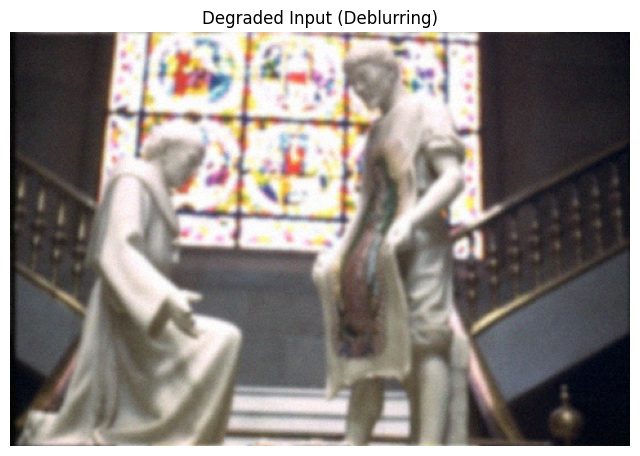


Running PLM...


/content/gdrive/My Drive/HPPP/Prox_PnP/PnP_restoration/utils/RGB_utils_sr.py:547: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /pytorch/torch/csrc/autograd/python_variable_indexing.cpp:347.)
  input = torch.cat([input, input[[slice(None)] * (dimension - 1) +
/content/gdrive/My Drive/HPPP/Prox_PnP/PnP_restoration/utils/RGB_utils_sr.py:549: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /pytorch/torch/csrc/autograd/python_variable_indexing.cpp:347.)


--- Reconstructed Image by PLM ---


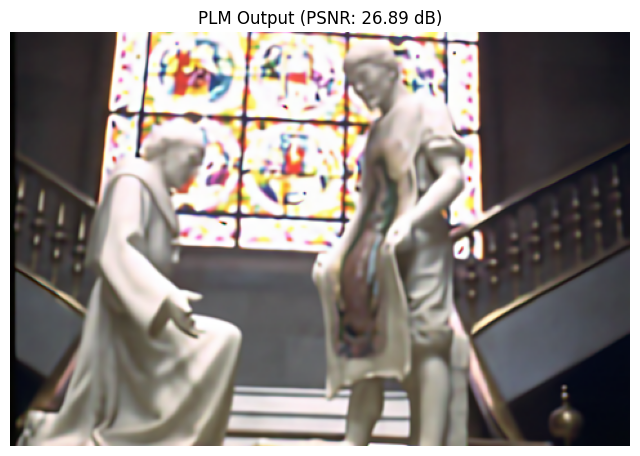

PLM finished in 377.16s | PSNR: 26.89 | SSIM: 0.8782

Running RED...
--- Reconstructed Image by RED ---


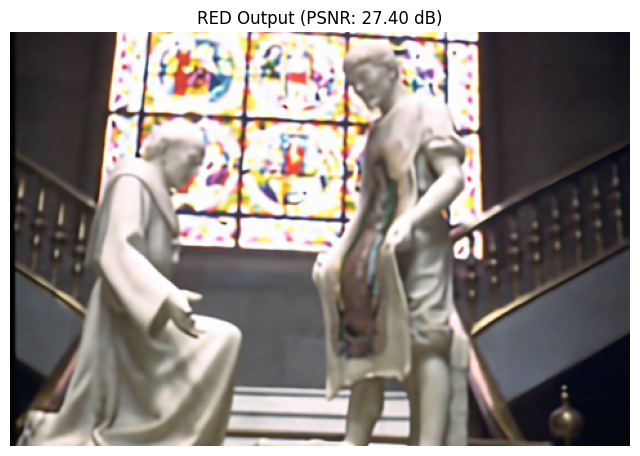

RED finished in 375.93s | PSNR: 27.40 | SSIM: 0.8893

Running REDPRO...
--- Reconstructed Image by REDPRO ---


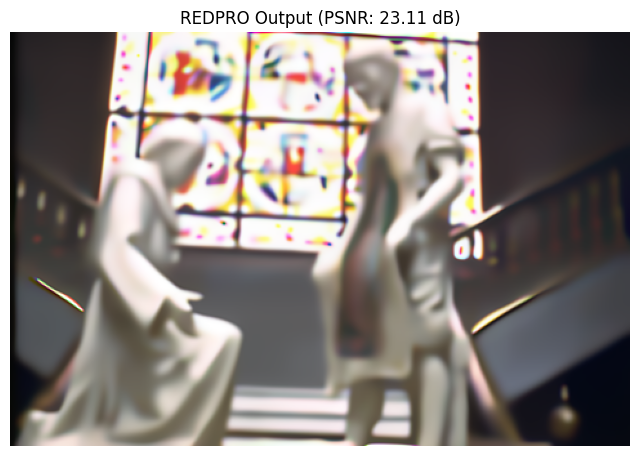

REDPRO finished in 376.83s | PSNR: 23.11 | SSIM: 0.7369

Running CRED...
--- Reconstructed Image by CRED ---


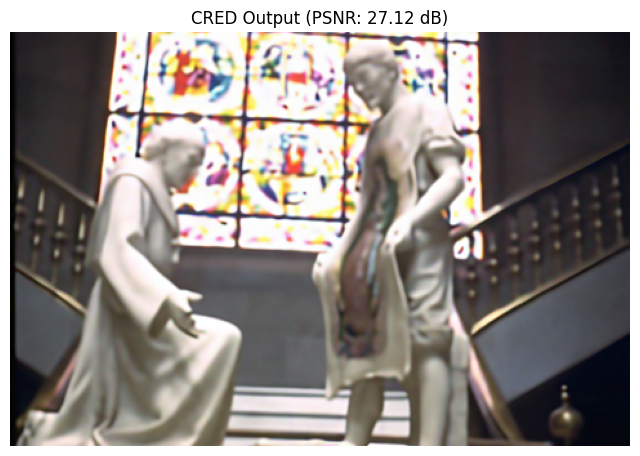

CRED finished in 383.05s | PSNR: 27.12 | SSIM: 0.8832

Running GraRED_HP3...
--- Reconstructed Image by GraRED_HP3 ---


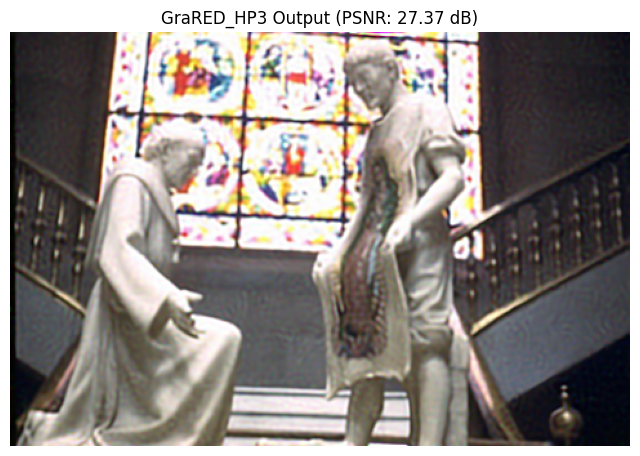

GraRED_HP3 finished in 351.33s | PSNR: 27.37 | SSIM: 0.8647

Running GraRED_GS_HP3...
--- Reconstructed Image by GraRED_GS_HP3 ---


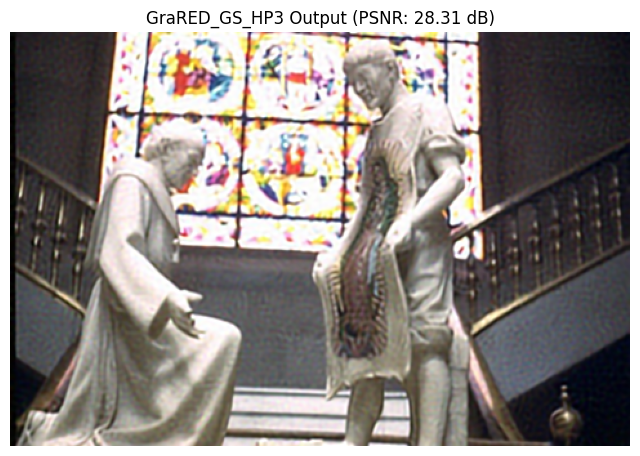

GraRED_GS_HP3 finished in 424.03s | PSNR: 28.31 | SSIM: 0.8667

--- Generating Final Convergence Plot ---


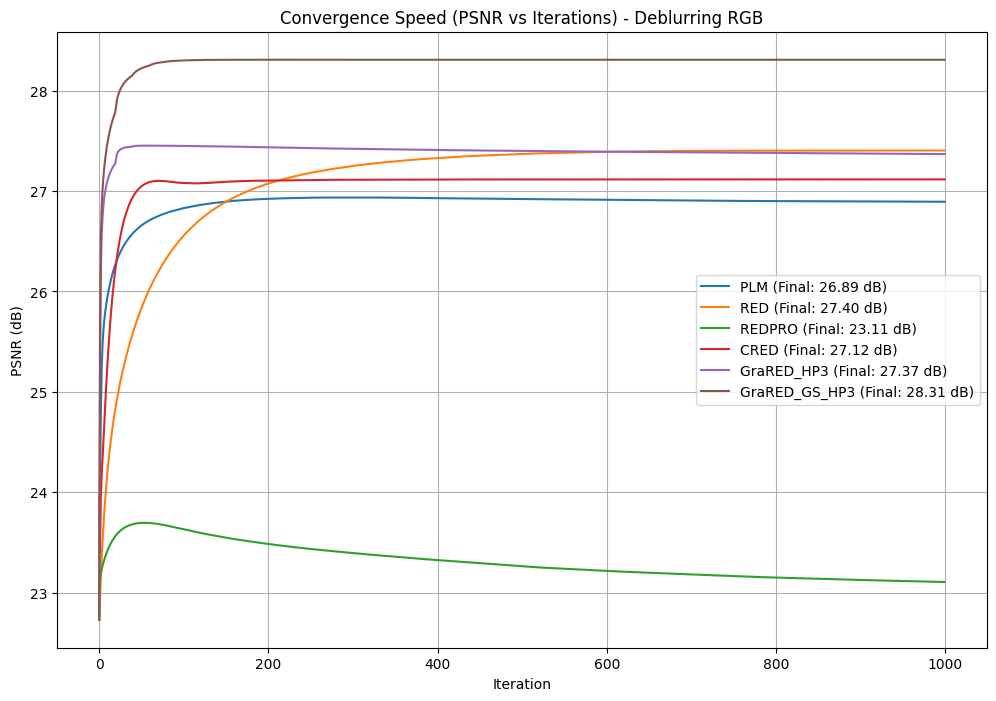


--- Generating Final Difference Plot ---


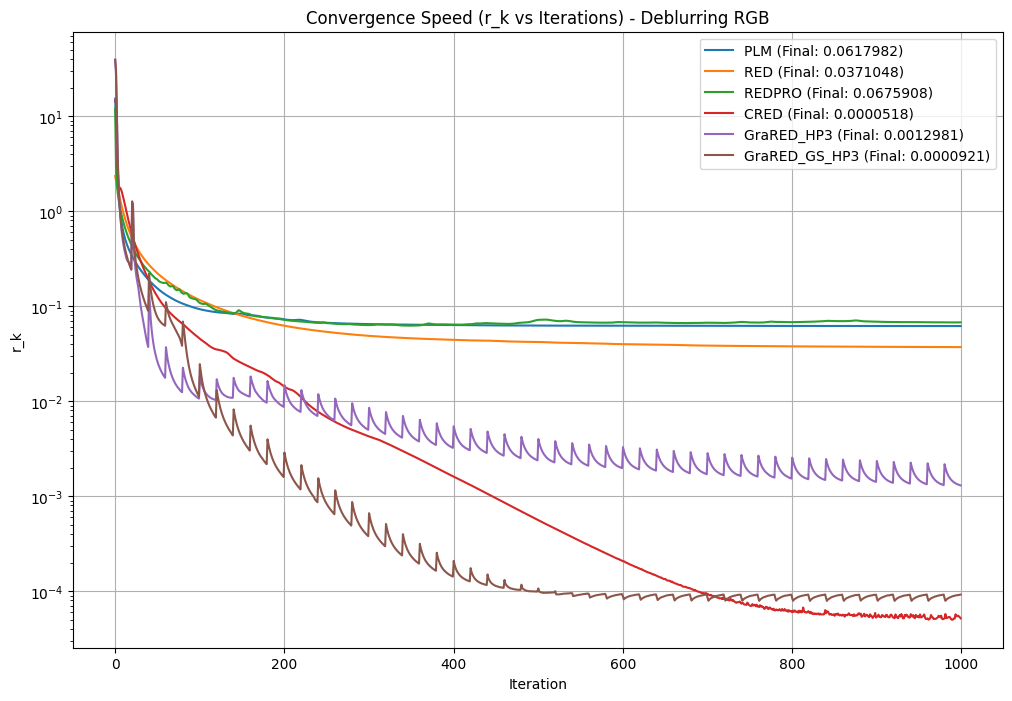



             FINAL RESULTS TABLE
    Algorithm  Time (s)  Final PSNR (dB)  Final Diff   SSIM
          PLM    377.16            26.89    0.061798 0.8782
          RED    375.93            27.40    0.037105 0.8893
       REDPRO    376.83            23.11    0.067591 0.7369
         CRED    383.05            27.12    0.000052 0.8832
   GraRED_HP3    351.33            27.37    0.001298 0.8647
GraRED_GS_HP3    424.03            28.31    0.000092 0.8667


In [ ]:
if __name__ == '__main__':
    import time
    import pandas as pd
    from skimage.metrics import structural_similarity as ssim
    from scipy import ndimage
    from scipy.ndimage import gaussian_filter
    import matplotlib.pyplot as plt
    import torch
    import numpy as np
    import os
    import sys

    ycbcr_mode = False
    kernel_path = '/content/gdrive/MyDrive/HPPP/Prox_PnP/PnP_restoration/kernels/Levin09.mat'
    kernels = hdf5storage.loadmat(kernel_path)

    if 'set12' in args.dataset:
        test_path = './Prox_PnP/datasets/set12/'
        test_imgs = os.listdir(test_path)
    else:
        # Reduce the number of images for faster testing
        test_imgs = ['butterfly'] # e.g. a single image for debugging

    img_type = 'RGB'

    # ======== Task selection ========
    # 'Inpainting'
    # 'Deblurring'
    task = 'Deblurring'
    noise_level = args.noise_level

    print('task: ', task)
    print('noise_level: ', noise_level)

    device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
    model_type = 'RealSN_DnCNN'
    sys.path.append(os.path.join(os.getcwd(), 'Provable_PnP'))

    f = load_model(model_type, 5, device)
    GS_model = initialize_cuda_color_denoiser(device)

    results_table = []
    psnr_histories = {}
    diff_histories = {}

    # Pick an image
    img_name = test_imgs[9]
    img_path = test_path + img_name
    input_im_uint = imread_uint(img_path, n_channels=3)
    input_im = np.float32(input_im_uint / 255)

    # ======== Build the degradation according to the task ========
    if task == 'Inpainting':
        Sf = 1
        np.random.seed(seed=0)
        mask = (np.random.rand(input_im.shape[0], input_im.shape[1]) > 0.5).astype(np.float32)
        k = mask
        blur_im = input_im * np.expand_dims(mask, axis=2)
        degradation_mode = 'inpainting'

    else:
        # Blur mode (Deblurring)
        Sf = 1  # 1 = blur only, >1 = super-resolution

        # Build a Gaussian blur filter (PSF)
        psf_size = 25
        sigma_blur = 1.6
        k = np.zeros((psf_size, psf_size))
        k[psf_size//2, psf_size//2] = 1
        k = gaussian_filter(k, sigma=sigma_blur)
        k = k / np.sum(k)  # normalize the kernel

        # Apply the blur using your own code

        if Sf > 1:  # super-resolution
            blur_im = numpy_degradation(input_im, k, sf=Sf)
        else:       # debluring
            # In newer scipy versions, use ndimage.convolve instead of ndimage.filters
            blur_im = ndimage.convolve(input_im, np.expand_dims(k, axis=2), mode='wrap')

        degradation_mode = 'deblurring'

    # Add noise in both cases
    np.random.seed(seed=0)
    noise = np.random.normal(0, noise_level / 255., blur_im.shape)
    blur_im += noise
    blur_im = np.clip(blur_im, 0, 1) # clamp values
    prox_noise_norm = np.sqrt((noise_level / 255.)**2 * blur_im.shape[0] * blur_im.shape[1] * blur_im.shape[2])

    img_tensor = array2tensor(blur_im).to(device)
    x0 = img_tensor
    x_gt = input_im_uint

    # Initialize the operators
    FB, FBC, F2B, FBFy, k_tensor = initialize_prox(img_tensor, degradation_mode, k, Sf, device)


    # === Fix the filter shape for RGB images in Deblurring mode ===

    if degradation_mode == 'deblurring' and k_tensor.dim() == 4 and k_tensor.shape[0] == 1 and k_tensor.shape[1] == 3:
        # convert [1, 3, 25, 25] to [3, 1, 25, 25]
        k_tensor = k_tensor.permute(1, 0, 2, 3)
        print(f"k_tensor shape fixed for RGB: {k_tensor.shape}")

    if noise_level <= 5.0: sigma_f = 5
    elif 15 >= noise_level > 5: sigma_f = 15
    else: sigma_f = 25

    # algorithms = ['GraRED_HP3','GraRED_GS_HP3','SCFP_LFP_PnP', 'SAM_PRO_v2', 'PnP_FBS', 'SAM_PRO_v1', 'PLM', 'RED', 'REDPRO', 'CRED']
    algorithms = ['PLM', 'RED',  'REDPRO', 'CRED', 'GraRED_HP3', 'GraRED_GS_HP3']
    #algorithms = ['PLM', 'GraRED_HP3', 'GraRED_GS_HP3']


    # 1. Show the degraded (noisy) input image
    print("\n--- Input Degraded Image ---")
    plt.figure(figsize=(8, 8))
    plt.imshow(tensor2uint(x0))
    plt.title(f"Degraded Input ({task})")
    plt.axis('off')
    plt.show()

    for algo in algorithms:
        print(f"\n{'='*30}\nRunning {algo}...\n{'='*30}")
        start_time = time.time()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        # Use no_grad to avoid memory leak (OOM)
        with torch.no_grad():
            if algo == 'PLM':
                opt_SCFP={'model_type': model_type, 'n_channels':3, 'alpha':1, 'beta':0.3, 'sigma':noise_level, 'sigma_norm':prox_noise_norm-0.2, 'sigma_f':sigma_f, 'K':1000, 'sf': Sf, 'gt':x_gt}
                x1, _, psnr_history, diff_history = PLM(x0, img_tensor, k_tensor, degradation_mode, FB, FBC, f, opt_SCFP)

            elif algo == 'RED':
                opt_RED={'model_type': model_type, 'alpha':1*noise_level, 'beta':0.1, 'sigma':noise_level, 'sigma_f':sigma_f, 'K':1000, 'lambda':0.1,'input_sigma':noise_level**2, 'sf': Sf, 'gt':x_gt}
                x1, _, psnr_history, diff_history = RED(x0, img_tensor, k_tensor, degradation_mode, FB, FBC, FBFy, f, opt_RED)

            elif algo == 'REDPRO':
                opt_REDPRO={'model_type': model_type, 'alpha':noise_level, 'beta':1, 'sigma':noise_level, 'sigma_f':sigma_f, 'K':1000, 'lambda':0.05,'input_sigma':noise_level**2, 'sf': Sf, 'gt':x_gt}
                x1, _, psnr_history, diff_history = REDPRO(x0, img_tensor, k_tensor, degradation_mode, FB, FBC, FBFy, f, opt_REDPRO)

            elif algo == 'CRED':
                opt_CRED={'model_type': model_type, 'n_channels':3, 'alpha':1, 'beta':1, 'sigma':noise_level, 'sigma_norm':0.98*prox_noise_norm, 'sigma_f':sigma_f, 'K':1000, 'sf': Sf, 'gt':x_gt}
                x1, _, psnr_history, diff_history = CRED_ADMM(x0, img_tensor, k_tensor, degradation_mode, FB, F2B, FBC, f, opt_CRED)

            elif algo == 'GraRED_HP3':
                opt_RED_HP3={'anchor_type': 'restart', 'q':20, 'tau':2.4, 's':1/2.4,'sigma':noise_level, 'lambda':30, 'K':1000, 'sf': Sf, 'gt':x_gt}
                y0, xa, ya = x0, x0, x0
                x1, _, psnr_history, diff_history = GraRED_HP3(x0, y0, xa, ya, img_tensor, k_tensor, degradation_mode, FB, FBC, F2B, FBFy, f, opt_RED_HP3, device)

            elif algo == 'GraRED_GS_HP3':
                opt_GS_HP3={'anchor_type': 'restart', 'q':20, 'tau':2.4, 's':1/2.4,'sigma':noise_level, 'sigma_denoiser':5,'lambda':30, 'K':1000, 'sf': Sf, 'gt':x_gt}
                y0, xa, ya = x0, x0, x0
                x1, _, psnr_history, diff_history = GraRED_GS_HP3(x0, y0, xa, ya, img_tensor, k_tensor, degradation_mode, FB, FBC, F2B, FBFy, GS_model, opt_GS_HP3, device)

            elif algo == 'SCFP_LFP_PnP':
                opt = {'alpha':1.0, 'beta':0.1, 'sigma':noise_level, 'sigma_norm':prox_noise_norm-0.2, 'sigma_f':sigma_f, 'K':1000, 'sf': Sf, 'gt':x_gt}
                x1, _, psnr_history = SCFP_LFP_PnP(x0, img_tensor, k_tensor, degradation_mode, FB, FBC, f, opt)

            elif algo == 'SAM_PRO_v2':
                opt = {'alpha':4, 'beta':0.1, 'sigma':noise_level, 'mu_0':500, 'sigma_f':sigma_f, 'K':1000, 'sf': Sf, 'gt':x_gt}
                x1, _, _, psnr_history = SAM_PRO_v2(x0, img_tensor, k_tensor, degradation_mode, FB, FBC, FBFy, f, opt)

            elif algo == 'PnP_FBS':
                opt = {'beta':0.1, 'sigma':noise_level, 'sigma_f':sigma_f, 'K':1000, 'sf': Sf, 'gt':x_gt}
                x1, _, _, psnr_history = PnP_FBS(x0, img_tensor, k_tensor, degradation_mode, FB, FBC, FBFy, f, opt)

            elif algo == 'SAM_PRO_v1':
                opt = {'alpha':2, 'beta':0.1, 'sigma':noise_level, 'mu_0':500, 'sigma_f':sigma_f, 'K':1000, 'sf': Sf, 'gt':x_gt}
                x1, _, _, psnr_history = SAM_PRO_v1(x0, img_tensor, k_tensor, degradation_mode, FB, FBC, FBFy, f, opt)

        exec_time = time.time() - start_time

        # 1. Final computations
        x_est = tensor2uint(x1)
        final_psnr = calculate_psnr(x_gt, x_est)
        final_diff = diff_history[-1]
        final_ssim = ssim(x_gt, x_est, data_range=255, channel_axis=-1)

        # 2. Show the reconstructed image for this method
        print(f"--- Reconstructed Image by {algo} ---")
        plt.figure(figsize=(8, 8))
        plt.imshow(x_est)
        plt.title(f"{algo} Output (PSNR: {final_psnr:.2f} dB)")
        plt.axis('off')
        plt.show()

        # 3. Store the PSNR history (convert to float to avoid memory leak)
        psnr_histories[algo] = [float(p) for p in psnr_history]


        # 4. Store the DIFF history (convert to float to avoid memory leak)
        diff_histories[algo] = [float(p) for p in diff_history]

        # 5. Store in the table
        results_table.append({
            'Algorithm': algo,
            'Time (s)': round(exec_time, 2),
            'Final PSNR (dB)': round(final_psnr, 2),
            # to be changed
            'Final Diff': round(final_diff.item(), 7),
            'SSIM': round(final_ssim, 4)
        })

        print(f"{algo} finished in {exec_time:.2f}s | PSNR: {final_psnr:.2f} | SSIM: {final_ssim:.4f}")

        # Memory cleanup after each algorithm
        del x1, psnr_history
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    # Generating Final Convergence Plot
    print("\n--- Generating Final Convergence Plot ---")
    plt.figure(figsize=(12, 8))
    for algo, res in zip(algorithms, results_table):
        plt.plot(psnr_histories[algo], label=f"{algo} (Final: {res['Final PSNR (dB)']:.2f} dB)")



    plt.title(f'Convergence Speed (PSNR vs Iterations) - {task} RGB')
    plt.xlabel('Iteration')
    plt.ylabel('PSNR (dB)')
    plt.legend()
    plt.grid(True)
    plt.show()

    # Generating Final Difference Plot(r_k)
    print("\n--- Generating Final Difference Plot ---")
    plt.figure(figsize=(12, 8))
    for algo, res in zip(algorithms, results_table):
        plt.semilogy(diff_histories[algo], label=f"{algo} (Final: {res['Final Diff']:.7f})")



    plt.title(f'Convergence Speed (r_k vs Iterations) - {task} RGB')
    plt.xlabel('Iteration')
    plt.ylabel('r_k')
    plt.legend()
    plt.grid(True)
    plt.show()

    # Final results table
    print("\n\n" + "="*50)
    print("             FINAL RESULTS TABLE")
    print("="*50)
    df = pd.DataFrame(results_table)
    print(df.to_string(index=False))
    print("="*50)